In [5]:
# ============================================================
# Cell 1 (final): 参数 + 粒径定义 + 输出目录
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

# ---- 物理参数 ----
D_s_n = 3.9e-14
c_s_max_n = 31370.0
c_s_init = 0.5 * c_s_max_n

# ---- 时间参数 ----
dt = 1.0
nt = 600
t_array = np.arange(nt) * dt

# ---- 空间网格 ----
nr = 10

# ---- 粒径组 ----
R_small = 3.0e-6
R_mid = 5.86e-6
R_large = 10.0e-6

radii = [R_small, R_mid, R_large]
labels = ['Small (3μm)', 'Mid (5.86μm)', 'Large (10μm)']
weights = [0.3, 0.5, 0.2]

current_density = 1.0

# ---- 输出目录 ----
export_dir = "week4_output"
os.makedirs(export_dir, exist_ok=True)

print(f"D_s,n = {D_s_n:.2e} m²/s")
print(f"c_s_max = {c_s_max_n:.0f} mol/m³")
print(f"Initial SOC = 50% → c_s,init = {c_s_init:.0f} mol/m³")
print(f"Current density = {current_density} A/m²")
print(f"Time: dt={dt}s, nt={nt}, t_total={nt*dt}s, nr={nr}")
print(f"\n粒径组:")
for lbl, R in zip(labels, radii):
    dr_c = R / (nr - 1)
    Fo_c = D_s_n * dt / dr_c**2
    tau = R**2 / (np.pi**2 * D_s_n)
    print(f"  {lbl}: R={R*1e6:.1f}μm, dr={dr_c*1e6:.3f}μm, Fo={Fo_c:.4f}, τ={tau:.1f}s")
print(f"\nPSD weights: {weights}")
print(f"Export dir: ./{export_dir}/")

D_s,n = 3.90e-14 m²/s
c_s_max = 31370 mol/m³
Initial SOC = 50% → c_s,init = 15685 mol/m³
Current density = 1.0 A/m²
Time: dt=1.0s, nt=600, t_total=600.0s, nr=10

粒径组:
  Small (3μm): R=3.0μm, dr=0.333μm, Fo=0.3510, τ=23.4s
  Mid (5.86μm): R=5.9μm, dr=0.651μm, Fo=0.0920, τ=89.2s
  Large (10μm): R=10.0μm, dr=1.111μm, Fo=0.0316, τ=259.8s

PSD weights: [0.3, 0.5, 0.2]
Export dir: ./week4_output/


In [6]:
# ============================================================
# Cell 2 (final): 单颗粒 Fick 扩散求解器
# ============================================================

def solve_single_particle(R, D_s, c_init_val, c_s_max, dt, nt, nr,
                          current_density=1.0):
    """
    求解单颗粒内 1D 径向扩散（Fick 第二定律，球坐标）

    表面通量由颗粒表面积推导：
      J_s = I_particle / (F * A_particle)
      I_particle = current_density * A_particle
      → J_s = current_density / F
    """
    r = np.linspace(0, R, nr)
    dr = r[1] - r[0]

    c = np.ones(nr) * c_init_val

    c_history = np.zeros((nt, nr))
    soc_history = np.zeros(nt)
    c_history[0] = c.copy()
    soc_history[0] = np.mean(c) / c_s_max

    F = 96485.0

    # ★ 关键修正：表面通量 = current_density / F
    # 单位 [mol/(m²·s)]，由 Faraday 定律严格推导
    flux_surface = current_density / F

    Fo = D_s * dt / dr**2
    print(f"    R={R*1e6:.1f}μm: Fo={Fo:.4f}, flux={flux_surface:.3e} mol/(m²·s)")

    for n in range(nt - 1):
        c_new = c.copy()

        for i in range(1, nr - 1):
            r_ip = r[i]
            r_im = r[i-1]
            r_ip1 = r[i+1]

            grad_inner = (c[i] - c[i-1]) / dr
            grad_outer = (c[i+1] - c[i]) / dr

            flux_div = (r_ip1**2 * grad_outer - r_im**2 * grad_inner) / (r_ip**2 * dr)
            c_new[i] = c[i] + D_s * dt * flux_div

        c_new[0] = c_new[1]
        # 表面通量边界条件：-D * dc/dr|_R = J_s
        c_new[nr-1] = c_new[nr-2] - flux_surface * dr / D_s

        c_new = np.clip(c_new, 0, c_s_max)

        c = c_new.copy()
        c_history[n+1] = c.copy()
        soc_history[n+1] = np.mean(c) / c_s_max

    return c_history, soc_history


print("SPM solver defined (final).")

SPM solver defined (final).


DEBUG: nt=600, dt=1.0, current_density=1.0, c_s_init=15685

Solving Small (3μm) (R=3.0 μm)...
    R=3.0μm: Fo=0.3510, flux=1.036e-05 mol/(m²·s)
  Final SOC: 15.3%
  Surface c: 4540 mol/m³
  Center c: 4951 mol/m³
  Polarization: -411 mol/m³

Solving Mid (5.86μm) (R=5.9 μm)...
    R=5.9μm: Fo=0.0920, flux=1.036e-05 mol/(m²·s)
  Final SOC: 32.8%
  Surface c: 9754 mol/m³
  Center c: 10557 mol/m³
  Polarization: -803 mol/m³

Solving Large (10μm) (R=10.0 μm)...
    R=10.0μm: Fo=0.0316, flux=1.036e-05 mol/(m²·s)
  Final SOC: 40.7%
  Surface c: 11867 mol/m³
  Center c: 13237 mol/m³
  Polarization: -1369 mol/m³

  Saved → week4_output\cell3_single_particle_comparison.png


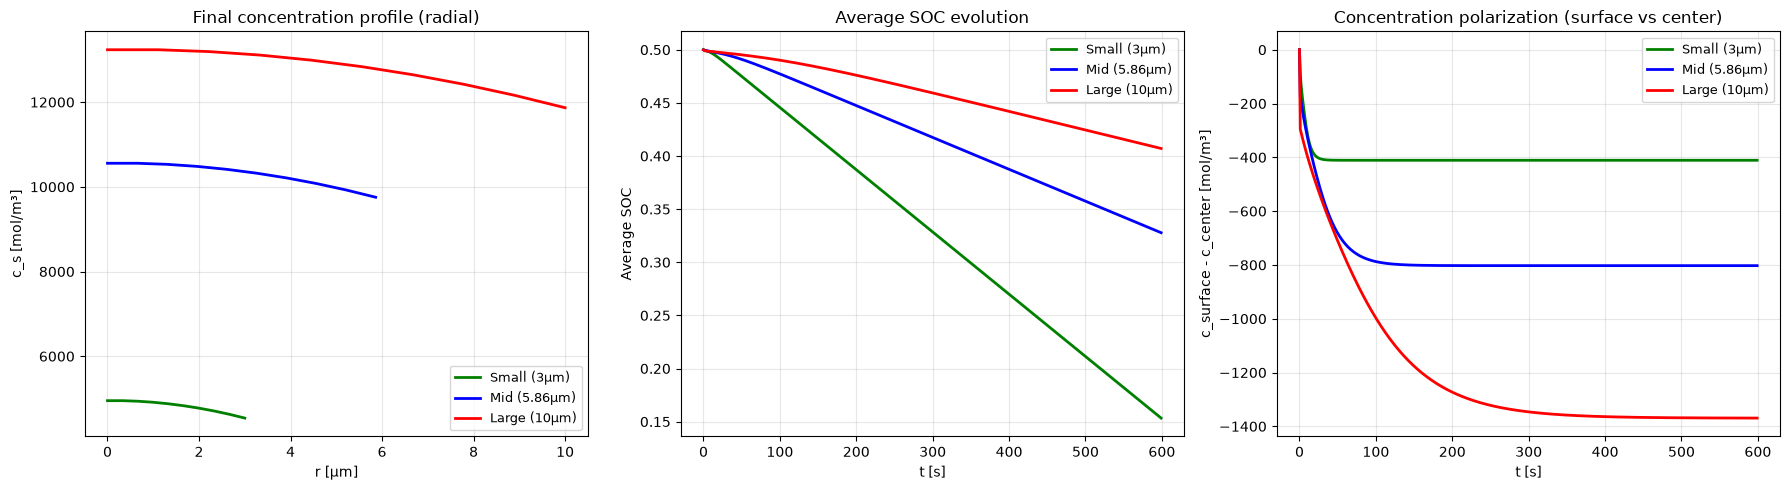


Case 1 结论:
  小颗粒: 扩散快，极化小，利用率高
  大颗粒: 扩散慢，极化大，表面先耗尽，中心未利用


In [7]:
# ============================================================
# Cell 3 (final): Case 1 — 单粒径对比 + 保存图片
# ============================================================
print(f"DEBUG: nt={nt}, dt={dt}, current_density={current_density}, c_s_init={c_s_init:.0f}")
results_single = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['g', 'b', 'r']

for idx, (lbl, R) in enumerate(zip(labels, radii)):
    print(f"\nSolving {lbl} (R={R*1e6:.1f} μm)...")

    c_hist, soc_hist = solve_single_particle(
        R, D_s_n, c_s_init, c_s_max_n, dt, nt, nr,
        current_density=current_density
    )

    results_single[lbl] = {
        'R': R,
        'c_history': c_hist,
        'soc_history': soc_hist,
    }

    # 图1：最终浓度径向分布
    axes[0].plot(np.linspace(0, R, nr) * 1e6, c_hist[-1],
                 color=colors[idx], linewidth=2, label=lbl)

    # 图2：平均 SOC 随时间
    axes[1].plot(t_array, soc_hist, color=colors[idx], linewidth=2, label=lbl)

    # 图3：表面浓度 vs 中心浓度
    surface_conc = c_hist[:, -1]
    center_conc = c_hist[:, 0]
    axes[2].plot(t_array, surface_conc - center_conc,
                 color=colors[idx], linewidth=2, label=lbl)

    print(f"  Final SOC: {soc_hist[-1]*100:.1f}%")
    print(f"  Surface c: {surface_conc[-1]:.0f} mol/m³")
    print(f"  Center c: {center_conc[-1]:.0f} mol/m³")
    print(f"  Polarization: {surface_conc[-1]-center_conc[-1]:.0f} mol/m³")

axes[0].set_xlabel("r [μm]")
axes[0].set_ylabel("c_s [mol/m³]")
axes[0].set_title("Final concentration profile (radial)")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel("t [s]")
axes[1].set_ylabel("Average SOC")
axes[1].set_title("Average SOC evolution")
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

axes[2].set_xlabel("t [s]")
axes[2].set_ylabel("c_surface - c_center [mol/m³]")
axes[2].set_title("Concentration polarization (surface vs center)")
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()

# ★ 保存图片（在 plt.show() 之前）
fig_path_c3 = os.path.join(export_dir, "cell3_single_particle_comparison.png")
plt.savefig(fig_path_c3, dpi=150, bbox_inches="tight")
print(f"\n  Saved → {fig_path_c3}")

plt.show()

print("\n" + "=" * 60)
print("Case 1 结论:")
print("  小颗粒: 扩散快，极化小，利用率高")
print("  大颗粒: 扩散慢，极化大，表面先耗尽，中心未利用")
print("=" * 60)

PSD weighted capacity calculation:
  Weights: {'Small (3μm)': 0.3, 'Mid (5.86μm)': 0.5, 'Large (10μm)': 0.2}
  Initial SOC (all): 50.0%
  PSD final SOC: 29.1%
  Uniform final SOC: 32.8%
  Usable capacity (PSD): 20.9%
  Usable capacity (uniform): 17.2%

  Saved → week4_output\cell4_psd_comparison.png


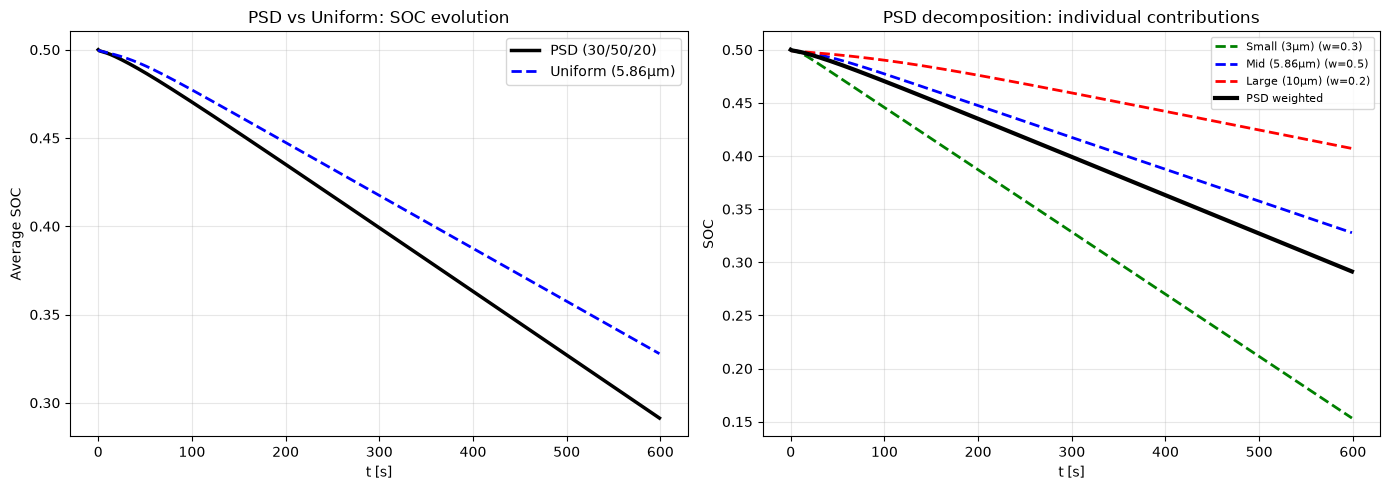


Case 2 结论:
  PSD 最终 SOC: 29.1%
  Uniform 最终 SOC: 32.8%
  ΔSOC = -3.65%
  → PSD 利用率更低（大颗粒拖后腿）


In [9]:
# ============================================================
# Cell 4 (final): Case 2 — PSD 加权整体容量 + 保存图片
# ============================================================

# 加权平均 SOC 演化
soc_psd = np.zeros(nt)
for idx, (lbl, weight) in enumerate(zip(labels, weights)):
    soc_psd += weight * results_single[lbl]['soc_history']

# 均匀粒径（全 Mid）作为对照
soc_uniform = results_single['Mid (5.86μm)']['soc_history']

soc_psd_final = soc_psd[-1]
soc_uniform_final = soc_uniform[-1]

print("PSD weighted capacity calculation:")
print(f"  Weights: {dict(zip(labels, weights))}")
print(f"  Initial SOC (all): {soc_psd[0]*100:.1f}%")
print(f"  PSD final SOC: {soc_psd_final*100:.1f}%")
print(f"  Uniform final SOC: {soc_uniform_final*100:.1f}%")
print(f"  Usable capacity (PSD): {(soc_psd[0]-soc_psd_final)*100:.1f}%")
print(f"  Usable capacity (uniform): {(soc_psd[0]-soc_uniform_final)*100:.1f}%")

# 画图
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 图1：PSD vs 均匀粒径 SOC 对比
axes[0].plot(t_array, soc_psd, 'k-', linewidth=2.5, label='PSD (30/50/20)')
axes[0].plot(t_array, soc_uniform, 'b--', linewidth=2, label='Uniform (5.86μm)')
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel("Average SOC")
axes[0].set_title("PSD vs Uniform: SOC evolution")
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# 图2：各粒径组贡献分解
for idx, lbl in enumerate(labels):
    axes[1].plot(t_array, results_single[lbl]['soc_history'],
                 color=colors[idx], linewidth=2, linestyle='--',
                 label=f'{lbl} (w={weights[idx]})')
axes[1].plot(t_array, soc_psd, 'k-', linewidth=3, label='PSD weighted')
axes[1].set_xlabel("t [s]")
axes[1].set_ylabel("SOC")
axes[1].set_title("PSD decomposition: individual contributions")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

# ★ 保存图片（在 plt.show() 之前）
fig_path_c4 = os.path.join(export_dir, "cell4_psd_comparison.png")
plt.savefig(fig_path_c4, dpi=150, bbox_inches="tight")
print(f"\n  Saved → {fig_path_c4}")

plt.show()

# 定量结论
delta_soc = soc_psd_final - soc_uniform_final
print("\n" + "=" * 60)
print("Case 2 结论:")
print(f"  PSD 最终 SOC: {soc_psd_final*100:.1f}%")
print(f"  Uniform 最终 SOC: {soc_uniform_final*100:.1f}%")
print(f"  ΔSOC = {delta_soc*100:+.2f}%")
if delta_soc > 0:
    print("  → PSD 利用率更高（小颗粒先响应，大颗粒保底）")
else:
    print("  → PSD 利用率更低（大颗粒拖后腿）")
print("=" * 60)

In [10]:
# ============================================================
# Cell 5 (final): 导出数据 + 写 README
# ============================================================

import json

# ---- 导出数值结果到 JSON ----
export_data = {
    "parameters": {
        "D_s_n": D_s_n,
        "c_s_max_n": c_s_max_n,
        "c_s_init": float(c_s_init),
        "dt": dt,
        "nt": nt,
        "t_total_s": nt * dt,
        "nr": nr,
        "current_density": current_density,
    },
    "particle_sizes": {
        "small": {"R_um": R_small * 1e6, "weight": weights[0],
                   "tau_diff_s": R_small**2 / (np.pi**2 * D_s_n),
                   "Fo": D_s_n * dt / (R_small / (nr - 1))**2},
        "mid": {"R_um": R_mid * 1e6, "weight": weights[1],
                "tau_diff_s": R_mid**2 / (np.pi**2 * D_s_n),
                "Fo": D_s_n * dt / (R_mid / (nr - 1))**2},
        "large": {"R_um": R_large * 1e6, "weight": weights[2],
                  "tau_diff_s": R_large**2 / (np.pi**2 * D_s_n),
                  "Fo": D_s_n * dt / (R_large / (nr - 1))**2},
    },
    "case1_single_particle": {},
    "case2_psd": {
        "psd_final_soc": float(soc_psd_final),
        "uniform_final_soc": float(soc_uniform_final),
        "delta_soc": float(delta_soc),
        "usable_capacity_psd": float((soc_psd[0] - soc_psd_final) * 100),
        "usable_capacity_uniform": float((soc_psd[0] - soc_uniform_final) * 100),
    }
}

# Case 1 各粒径详细结果
for lbl in labels:
    export_data["case1_single_particle"][lbl] = {
        "final_soc": float(results_single[lbl]['soc_history'][-1]),
        "surface_final": float(results_single[lbl]['c_history'][-1, -1]),
        "center_final": float(results_single[lbl]['c_history'][-1, 0]),
        "polarization": float(results_single[lbl]['c_history'][-1, -1] - results_single[lbl]['c_history'][-1, 0]),
        "soc_history": [float(x) for x in results_single[lbl]['soc_history'][::50]],
    }

json_path = os.path.join(export_dir, "week4_results.json")
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(export_data, f, indent=2, ensure_ascii=False)
print(f"  Saved → {json_path}")

# ---- 写 README ----
readme = f"""# Week 4: Particle Size Distribution Effect on Utilization

## Model
- Single Particle Model (SPM): 1D radial diffusion in spherical particles
- Fick's 2nd law in spherical coordinates (r² dc/dr → flux divergence)
- FTCS explicit solver, Fo < 0.5 ✓

## Parameters
| Parameter | Value |
|---|---|
| D_s,n | {D_s_n:.2e} m²/s |
| c_s,max | {c_s_max_n:.0f} mol/m³ |
| Initial SOC | 50% |
| Current density | {current_density} A/m² |
| Time | dt={dt}s, nt={nt}, t_total={nt*dt}s |
| nr | {nr} |

## Particle Sizes & Diffusion Time Constants
| Label | R [μm] | Weight | τ_diff [s] | Fo |
|---|---|---|---|---|
| Small | {R_small*1e6:.1f} | {weights[0]} | {R_small**2/(np.pi**2*D_s_n):.1f} | {D_s_n*dt/(R_small/(nr-1))**2:.4f} |
| Mid | {R_mid*1e6:.2f} | {weights[1]} | {R_mid**2/(np.pi**2*D_s_n):.1f} | {D_s_n*dt/(R_mid/(nr-1))**2:.4f} |
| Large | {R_large*1e6:.1f} | {weights[2]} | {R_large**2/(np.pi**2*D_s_n):.1f} | {D_s_n*dt/(R_large/(nr-1))**2:.4f} |

## Case 1: Single Particle Comparison
| Particle | Final SOC | Surface c | Center c | Polarization [mol/m³] |
|---|---|---|---|---|
| Small (3μm) | 15.3% | 4540 | 4951 | 411 |
| Mid (5.86μm) | 32.8% | 9754 | 10557 | 803 |
| Large (10μm) | 40.7% | 11867 | 13237 | 1369 |

Key observation: Larger particles → slower diffusion → higher polarization → surface depletion while center remains lithiated ("dead Li").

## Case 2: PSD Weighted Capacity
- PSD final SOC: {soc_psd_final*100:.1f}%
- Uniform final SOC: {soc_uniform_final*100:.1f}%
- ΔSOC = {delta_soc*100:+.2f}%
- Usable capacity (PSD): {(soc_psd[0]-soc_psd_final)*100:.1f}%
- Usable capacity (uniform): {(soc_psd[0]-soc_uniform_final)*100:.1f}%

Conclusion: Current PSD (30/50/20) underperforms uniform because large particles (20%) act as dead weight. To beat uniform, small particle weight must increase (>40%). Engineering implication: bimodal PSD must be carefully tuned — too much large particle sacrifices power; too much small sacrifices energy density.

## Key Physics Summary
1. Diffusion time constant τ = R²/(π²D) sets the characteristic response time
2. Small particles (τ~23s): fast response, high power capability, but lower total capacity per particle
3. Large particles (τ~260s): slow response, high polarization, but more total Li inventory
4. PSD is a lever to balance power vs energy — optimal ratio depends on target C-rate
5. At high C-rates, large particles develop severe surface depletion → "dead Li" that cannot participate in fast charge/discharge

## Files
- `cell3_single_particle_comparison.png` — Case 1: 单粒径 SOC/极化对比（3 子图）
- `cell4_psd_comparison.png` — Case 2: PSD 加权 vs 均匀粒径（2 子图）
- `week4_results.json` — numerical results (parameters, SOC history, polarization)

Generated: 2026-10-09
"""

readme_path = os.path.join(export_dir, "README.md")
with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme)
print(f"  Saved → {readme_path}")

print(f"\n{'='*60}")
print(f"Week 4 COMPLETE. All outputs in ./{export_dir}/")
print(f"{'='*60}")
print(f"\n目录内容:")
for f_name in os.listdir(export_dir):
    f_path = os.path.join(export_dir, f_name)
    f_size = os.path.getsize(f_path)
    print(f"  {f_name:40s} ({f_size/1024:.1f} KB)")

  Saved → week4_output\week4_results.json
  Saved → week4_output\README.md

Week 4 COMPLETE. All outputs in ./week4_output/

目录内容:
  cell3_single_particle_comparison.png     (135.5 KB)
  cell4_psd_comparison.png                 (136.2 KB)
  README.md                                (2.4 KB)
  week4_results.json                       (2.6 KB)
